# Rapport final — Optimisation de tournées de livraison (CVRP)

**Projet CesiCDP — Réponse à l'appel à manifestation d'intérêt de l'ADEME**

Ce rapport rassemble la modélisation mathématique formelle, l'analyse de complexité théorique, la résolution exacte par PLNE et Branch and Bound, l'algorithme génétique et l'étude expérimentale comparative complète sur 23 instances de référence VRPLIB. Le périmètre implémenté est le **CVRP niveau B** : dépôt unique, flotte homogène, capacité identique, demandes clients strictement positives et coûts d'arcs euclidiens symétriques.

**Résumé méthodologique.** 
1. Nous posons d'abord le problème et sa **formulation mathématique rigoureuse en PLNE** (variables, fonction objectif, contraintes de visite, de flot, de capacité et d'élimination des sous-tours).
2. À partir de cette formulation, nous menons l'**analyse théorique de complexité** : preuve d'appartenance à la classe NP et preuve de NP-difficulté au sens fort par réduction polynomiale du problème du voyageur de commerce (TSP).
3. Le **GA est la méthode retenue pour les grandes instances**. Le PLNE sert de référence sur les petites instances, afin de certifier certains optima et d'évaluer la qualité du GA.

---

**Plan du rapport**
1. Contexte et périmètre industriel
2. Données et modélisation mathématique en PLNE
3. Analyse théorique de complexité (NP-complétude & Réduction)
4. Du PLNE de référence au choix du GA
5. Choix du jeu d'essai expérimental (23 instances de référence VRPLIB)
6. Résolution exacte : PLNE et Branch and Bound (résultats et limites expérimentales)
7. Métaheuristique retenue : Algorithme Génétique (Architecture, Schéma fonctionnel, Décodage Split)
8. Étude expérimentale comparative et analyse des performances
9. Conclusion, limites et Plan d'Amélioration Stratégique
10. Références bibliographiques


## 1. Contexte et périmètre industriel

Dans le cadre de l'appel à manifestation d'intérêt de l'ADEME, l'entreprise **CesiCDP** souhaite optimiser ses tournées de livraison de marchandises afin de minimiser les distances parcourues, réduire la consommation d'énergie fossile et abaisser l'empreinte carbone de ses opérations logistiques urbaines.

Une flotte de véhicules utilitaires légers identiques, basée à un dépôt central unique, doit desservir un ensemble de clients répartis géographiquement. Chaque client émet une demande connue en volume ou en masse. Le coût associé au déplacement entre deux points représente la distance euclidienne ou le temps de trajet routier.

Conformément au cahier des charges, ce projet retient le **périmètre standard du CVRP (Capacitated Vehicle Routing Problem - niveau B)** :
- **Dépôt unique** : tous les véhicules partent du dépôt et y reviennent impérativement à la fin de leur tournée ;
- **Flotte homogène** : les véhicules disposent tous de la même capacité maximale d'emport $Q$ ;
- **Demandes déterministes** : chaque client a une demande strictement positive $q_i > 0$, connue à l'avance et inférieure ou égale à la capacité $Q$ ;
- **Visite unique** : chaque client est livré exactement une fois par un seul et unique véhicule ;
- **Coûts symétriques et fixes** : les distances respectent l'inégalité triangulaire et ne dépendent pas de l'heure.

L'objectif est d'organiser les tournées de manière à **minimiser la distance totale parcourue** par l'ensemble de la flotte tout en respectant l'intégralité des contraintes opérationnelles.


## 2. Données et modélisation mathématique en PLNE

Le réseau est un graphe complet orienté $G=(V,A)$, avec $C=\{1,\ldots,n\}$ les clients, $V=C\cup\{0\}$ le dépôt et les clients, $K=\{1,\ldots,m\}$ les véhicules, et $A=\{(i,j)\in V^2:i\ne j\}$ les arcs possibles. Chaque client $i$ a une demande $q_i>0$ avec $q_i\le Q$, chaque véhicule a une capacité $Q$, et $c_{ij}\ge0$ désigne le coût de déplacement de $i$ à $j$. Une condition nécessaire de faisabilité est $\sum_{i\in C}q_i\le mQ$.

Cette formulation utilise des variables **indexées par véhicule**. Cela permet de savoir non seulement quels arcs sont utilisés, mais aussi **quel camion** les emprunte. En contrepartie, il faut davantage de variables et de contraintes qu'avec une formulation qui ne distingue pas les véhicules. Elle s’inscrit dans le cadre général de la programmation linéaire présenté par [Techniques de l’ingénieur — Programmation linéaire](https://www.techniques-ingenieur.fr/ressources-documentaires/sciences-fondamentales-th8/mathematiques-ti052/programmation-lineaire-af1254) [2].

On note :
- $C=\{1,\ldots,n\}$ : ensemble des clients ;
- $V=C\cup\{0\}$ : clients et dépôt ;
- $K=\{1,\ldots,m\}$ : véhicules disponibles ;
- $A=\{(i,j)\in V^2:i\ne j\}$ : arcs possibles.

### 2.1 Variables de décision

- $x_{ijk}\in\{0,1\}$ : vaut 1 si le véhicule $k$ se déplace directement de $i$ vers $j$, et 0 sinon.
- $y_{ik}\in\{0,1\}$ : vaut 1 si le client $i$ est affecté au véhicule $k$.
- $z_k\in\{0,1\}$ : vaut 1 si le véhicule $k$ est utilisé.
- $u_{ik}\geq 0$ : quantité cumulée livrée par le véhicule $k$ jusqu'à sa visite du client $i$. Cette variable auxiliaire sert à modéliser la capacité et à éliminer les sous-tours.

**Pourquoi quatre familles de variables ?** Elles ne représentent pas la même décision : $x$ décrit les déplacements, $y$ l'affectation des clients, $z$ l'utilisation des camions et $u$ la progression de la charge cumulée. Une variable n'a pas besoin d'apparaître dans la fonction objectif pour être utile : elle peut servir uniquement aux contraintes.

### 2.2 Fonction objectif

On minimise le coût total des arcs empruntés par tous les véhicules :

$$\min Z=\sum_{k\in K}\sum_{(i,j)\in A}c_{ij}x_{ijk}$$

Ici, $c_{ij}$ représente la distance (en km) ou la durée (en minutes) entre $i$ et $j$. Comme $x_{ijk}=1$ uniquement si le véhicule $k$ emprunte cet arc, la somme additionne les coûts de toutes les tournées.

### 2.3 Contraintes

#### A. Chaque client est affecté à un seul véhicule

$$\sum_{k\in K}y_{ik}=1 \qquad \forall i\in C$$

Pour chaque client $i$, exactement un véhicule est choisi. Cette contrainte porte sur **l'affectation** des clients, pas directement sur les arcs.

#### B. Un client affecté au véhicule doit avoir une entrée et une sortie

$$\sum_{j\in V\setminus\{i\}}x_{ijk}=y_{ik}
\qquad \forall i\in C,\ k\in K$$

$$\sum_{j\in V\setminus\{i\}}x_{jik}=y_{ik}
\qquad \forall i\in C,\ k\in K$$

Si $y_{ik}=1$, le véhicule $k$ a exactement un arc sortant du client $i$ et un arc entrant dans ce client. Si $y_{ik}=0$, ces sommes valent 0 : ce véhicule ne visite pas ce client.

#### C. Chaque véhicule utilisé part du dépôt et y revient

$$\sum_{j\in C}x_{0jk}=z_k \qquad \forall k\in K$$

$$\sum_{i\in C}x_{i0k}=z_k \qquad \forall k\in K$$

Si $z_k=1$, le véhicule $k$ a un départ du dépôt et un retour au dépôt. Si $z_k=0$, il n'effectue aucun de ces déplacements.

#### D. Relier l'affectation à l'utilisation du véhicule

$$y_{ik}\leq z_k \qquad \forall i\in C,\ k\in K$$

Un véhicule inutilisé ($z_k=0$) ne peut pas se voir affecter de client. Cette contrainte rend explicite le lien entre les variables $y$ et $z$.

#### E. Respecter la capacité du véhicule

$$\sum_{i\in C}q_i y_{ik}\leq Qz_k \qquad \forall k\in K$$

La demande totale des clients affectés à un véhicule ne dépasse pas sa capacité $Q$. Si le véhicule n'est pas utilisé, $z_k=0$ et la contrainte impose qu'aucun client ne lui soit affecté.

#### F. Cohérence de charge et élimination des sous-tours

On borne d'abord la charge cumulée :

$$q_i y_{ik}\leq u_{ik}\leq Qy_{ik}
\qquad \forall i\in C,\ k\in K$$

Si le client $i$ n'est pas affecté au véhicule $k$, alors $y_{ik}=0$ et donc $u_{ik}=0$. S'il lui est affecté, la charge cumulée est au moins égale à la demande de ce client et ne dépasse pas $Q$. Le terme $q_j y_{jk}$ est essentiel : il désactive l’ajout de la demande de $j$ lorsque $j$ n’appartient pas au véhicule $k$.

Ensuite, pour deux clients distincts $i$ et $j$ :

$$u_{jk}\geq u_{ik}+q_j y_{jk}-Q(1-x_{ijk})
\qquad \forall k\in K,\ i,j\in C,\ i\ne j$$

**Si l'arc $i\to j$ est emprunté**, $x_{ijk}=1$ et la contrainte devient :

$$u_{jk}\geq u_{ik}+q_j y_{jk}=u_{ik}+q_j$$

La quantité cumulée augmente donc au moins de la demande $q_j$ du client suivant.

**Si l'arc $i\to j$ n'est pas emprunté**, $x_{ijk}=0$ et la contrainte devient $u_{jk}\geq u_{ik}+q_j y_{jk}-Q$, une borne valide car $0\leq u_{ik}\leq Q$ et $q_j y_{jk}\leq Q$.

La contrainte est relâchée lorsque l’arc n’est pas utilisé ; le terme d’activation doit inclure $y_{jk}$ pour rester valide entre véhicules.

Cette progression empêche un sous-tour formé uniquement de clients : si un cycle de clients était utilisé, la charge cumulée devrait augmenter d'une quantité strictement positive à chaque arc, puis revenir à son point de départ, ce qui est impossible.

#### G. Domaine des variables

$$x_{ijk},y_{ik},z_k\in\{0,1\},\qquad u_{ik}\geq 0$$

Les variables $x$, $y$ et $z$ sont binaires, tandis que $u$ est continue. Elle n'a pas besoin d'être entière pour que cette formulation fonctionne.

### 2.4 Limites et prolongements

Cette formulation suppose des coûts d’arcs fixes. Elle ne comprend pas de fenêtres horaires, de durée maximale de tournée, ni de trafic dépendant de l’heure. Ces extensions demanderaient des variables et contraintes supplémentaires.


## 3. Analyse théorique de complexité

Maintenant que le problème et sa formulation mathématique en PLNE sont établis, nous pouvons en analyser la complexité algorithmique intrinsèque.

### 3.1 Version décisionnelle du CVRP

La version d'optimisation du CVRP cherche le coût minimum $Z^*$. La **version décisionnelle** associée s'énonce ainsi :
> **Entrée :** Un graphe complet $G=(V, A)$, un ensemble de clients $C$ avec demandes $q_i$, un dépôt $0$, une capacité $Q$, une flotte maximale $m$, une matrice de coûts $c_{ij}$, et un seuil de coût rationnel $B > 0$.  
> **Question :** Existe-t-il un ensemble de tournées satisfaisant les contraintes du modèle (chaque client affecté à un seul véhicule, départ et retour au dépôt, au plus $m$ véhicules utilisés et respect de la capacité $Q$) et de coût total vérifiant $\sum_{k\in K}\sum_{(i,j)\in A} c_{ij}x_{ijk} \le B$ ?

---

### 3.2 Appartenance à la classe NP

Pour établir que le CVRP décisionnel appartient à la classe **NP**, on fournit comme certificat une liste de tournées ordonnées $\mathcal{R}=(R_1,\ldots,R_p)$, où chaque tournée est de la forme $R_k=(0,i_1,\ldots,i_r,0)$. Les véhicules sont identifiés par ces tournées ; il suffit ensuite de vérifier :

1. **Nombre de véhicules :** vérifier que $p\le m$.
2. **Départ et retour au dépôt :** vérifier que chaque tournée commence au dépôt $0$ et s'y termine.
3. **Visite unique :** vérifier que chaque client de $C$ apparaît exactement une fois dans l'ensemble des tournées.
4. **Capacité :** pour chaque tournée $R_k$, calculer la somme des demandes de ses clients et vérifier qu'elle est au plus $Q$.
5. **Seuil de coût :** additionner les coûts des arcs parcourus et vérifier que le coût total est au plus $B$.

Chaque contrôle se fait en temps polynomial dans la taille de l'entrée (linéaire en nombre de clients et de tournées, hors coût des opérations arithmétiques). Le certificat a lui-même une taille polynomiale. Les variables $x_{ijk}$, $y_{ik}$ et $z_k$ de la PLNE peuvent être déduites de ces tournées. Ainsi :

$$\boxed{\text{Le CVRP décisionnel appartient à la classe NP.}}$$

---

### 3.3 Réduction du TSP au CVRP
#### 3.3.1 Partir d’une instance du TSP

On considère une instance du TSP définie par :
- Un ensemble de villes $V=\{v_0,v_1,\ldots,v_n\}$.
- Un coût de déplacement $c_{ij}$ entre chaque paire de villes.
- Une borne de coût $B$.

#### 3.3.2 Construire une instance du CVRP
  
On transforme l'instance du TSP de la manière suivante :

| Instance du TSP | Instance correspondante du CVRP |
|---|---|
| Ville $v_0$ | Dépôt $v_0$ |
| Les $n$ villes restantes | Les $n$ sommets restants deviennent les clients $C$ |
| Coût de déplacement $c_{ij}$ | Même coût de déplacement $c_{ij}$ |
| Aucune demande des clients | Fixer la demande de chaque client à $q_i=1$ |
| Un seul véhicule | Fixer le nombre de véhicules à $m=1$ |
| Aucune contrainte de capacité | Fixer la capacité du véhicule à $Q=n$ |
| Borne de coût $B$ | Même borne de coût $B$ |

**Remarquons que cette transformation s'effectue en temps polynomial.**

#### 3.3.3 Démontrer l’équivalence des réponses

4.3.1. Si l'instance du TSP admet une tournée de coût inférieur ou égal à $B$, alors l'instance du CVRP admet également une solution de coût inférieur ou égal à $B$.

On fait suivre au véhicule du CVRP la tournée correspondant à la solution du TSP.
Cette tournée :
- Dessert chaque client exactement une fois.
- Respecte la capacité du véhicule $Q=n$.
- Commence et se termine au dépôt.
- Possède exactement le même coût total que la tournée du TSP.

Par conséquent, il s'agit d'une solution réalisable du CVRP dont le coût est inférieur ou égal à $B$.

4.3.2. Si l'instance du CVRP construite admet une solution de coût inférieur ou égal à $B$, alors l'instance du TSP admet également une tournée de coût inférieur ou égal à $B$.

Il n'y a qu'un seul véhicule effectuant une seule tournée, et chaque client doit être desservi exactement une fois.
Cette tournée satisfait donc les contraintes du TSP et possède un coût inférieur ou égal à $B$.

Puisque le TSP décisionnel est NP-complet, cette réduction montre que le CVRP décisionnel est NP-difficile. Avec son appartenance à NP établie à la section précédente, le CVRP décisionnel est donc **NP-complet**. Le problème d’optimisation CVRP associé est **NP-difficile**.

---

### 3.4 Conséquences théoriques et pratiques

1. **Absence d'algorithme polynomial exact :** Sauf si $P = NP$, il n'existe aucun algorithme capable de résoudre de façon exacte toutes les instances du CVRP en temps polynomial.
2. **Explosion combinatoire :** Le nombre de permutations possibles pour ordonner $n$ clients est $n!$. Même avec l'élagage efficace du Branch and Bound sur le modèle PLNE, la complexité dans le pire cas reste exponentielle.


## 4. Du PLNE de référence au choix du GA

Le choix du solveur dépend de la taille de l'instance et du niveau de garantie attendu. Le CVRP est un problème NP-difficile : cela signifie qu'aucun algorithme polynomial exact n'est connu. En particulier, sauf si $P = NP$, on ne peut pas attendre d'une méthode exacte qu'elle fournisse l'optimum en temps polynomial pour toutes les instances. Cette affirmation est une limite théorique, pas la preuve que chaque instance est difficile : certaines instances peuvent être résolues rapidement.

```mermaid
flowchart LR
    A["Problème CVRP (NP-difficile)"] --> B["Petites instances (n <= 30)"]
    A --> C["Moyennes et Grandes instances (n >= 40)"]
    
    B --> D["Méthode Exacte : PLNE (Branch and Bound)"]
    D --> E["• Optimalité prouvée si le solveur termine<br/>• Référence pour mesurer le gap<br/>• Temps potentiellement exponentiel"]
    
    C --> F["Métaheuristique : Algorithme Génétique"]
    F --> G["• Recherche bornée par un budget de calcul<br/>• Solutions réalisables rapidement<br/>• Aucune garantie d'optimalité"]

    style D fill:#4CAF50,color:#fff
    style F fill:#2196F3,color:#fff
```

### Pourquoi le PLNE est indispensable ?
- **Référence exacte :** Le Branch and Bound explore l'arbre de recherche et peut certifier l'optimum lorsqu'il termine. Son temps de calcul peut toutefois croître exponentiellement ; le PLNE n'est donc pas une méthode à temps polynomial garanti.
- **Étalonnage :** Sur les instances où l'optimum est prouvé, on calcule le gap de l'heuristique par rapport à cette référence. Si l'optimum n'est pas connu, on compare plutôt la solution à une borne inférieure et on indique clairement que le gap obtenu n'est alors pas un écart à l'optimum certifié.

### Pourquoi choisir un algorithme génétique pour les grandes instances ?
- **Temps de calcul maîtrisé :** Contrairement au Branch and Bound, qui peut devoir explorer un nombre exponentiel de sous-problèmes, le GA s'arrête après un nombre fixé de générations et d'évaluations. Pour une population de taille $P$, $G$ générations et un coût d'évaluation polynomial, ce budget donne un coût polynomial en $n$ lorsque $P$ et $G$ sont fixés.
- **Compromis pratique :** Le GA ne garantit ni l'optimum global ni un gap donné. Il est choisi parce qu'il peut produire des tournées réalisables dans un temps borné sur de grandes instances ; qualité et temps doivent être mesurés expérimentalement. Le PLNE reste utile pour les petites instances et pour comparer les résultats lorsque l'optimum est certifié.


## 5. Choix du jeu d'essai expérimental (23 instances de référence VRPLIB)

Pour répondre à l'exigence du cahier des charges de tester nos solveurs sur **au moins 20 instances de référence**, nous retenons un ensemble de **23 instances issues du benchmark académique officiel VRPLIB** (séries A, B, E et P de la littérature) présentes dans le dossier `data/` :

- **Série E** (*Christofides & Eilon, 1969*) : 4 instances (12 à 50 clients) ;
- **Série P** (*Augerat et al., 1995*) : 5 instances (15 à 49 clients) ;
- **Série B** (*Augerat et al., 1995*) : 5 instances (30 à 49 clients) ;
- **Série A** (*Augerat et al., 1995*) : 9 instances (31 à 79 clients).

**Rigueur méthodologique :**  
Chaque instance est accompagnée d'une **solution de référence** (fichier `.sol`). Cette valeur correspond à une meilleure solution connue/documentée et ne constitue pas, à elle seule, une preuve d'optimalité. Les gaps calculés dans l'étude sont donc des écarts à la référence ; le PLNE ne certifie l'optimum que lorsque son statut est `optimal`.


In [1]:
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from common import check_solution, route_cost, route_load, gap, plot_solution, load_instance
import algorithms.genetic_algorithm as ga
from algorithms.plne import branch_and_bound
from benchmark import load_benchmark_instances

pd.set_option('display.precision', 2)
DATA = Path('data')
all_instances = load_benchmark_instances()
for inst in all_instances:
    print(f'  {inst.name:10s} | {inst.n_customers:2d} clients | Q={inst.capacity:4d} | m={inst.n_vehicles:2d} | best_known={inst.best_known}')
vrplib_instances = all_instances
print(f'\n==> Total : {len(all_instances)} instances de référence VRPLIB chargées.')


  A-n32-k5   | 31 clients | Q= 100 | m= 5 | best_known=784.0
  A-n33-k5   | 32 clients | Q= 100 | m= 5 | best_known=661.0
  A-n37-k6   | 36 clients | Q= 100 | m= 6 | best_known=949.0
  A-n39-k5   | 38 clients | Q= 100 | m= 5 | best_known=822.0
  A-n45-k6   | 44 clients | Q= 100 | m= 6 | best_known=944.0
  A-n48-k7   | 47 clients | Q= 100 | m= 7 | best_known=1073.0
  A-n55-k9   | 54 clients | Q= 100 | m= 9 | best_known=1073.0
  A-n60-k9   | 59 clients | Q= 100 | m= 9 | best_known=1354.0
  A-n80-k10  | 79 clients | Q= 100 | m=10 | best_known=1763.0
  B-n31-k5   | 30 clients | Q= 100 | m= 5 | best_known=672.0
  B-n35-k5   | 34 clients | Q= 100 | m= 5 | best_known=955.0
  B-n39-k5   | 38 clients | Q= 100 | m= 5 | best_known=549.0
  B-n45-k6   | 44 clients | Q= 100 | m= 6 | best_known=678.0
  B-n50-k7   | 49 clients | Q= 100 | m= 7 | best_known=741.0
  E-n13-k4   | 12 clients | Q=6000 | m= 4 | best_known=247.0
  E-n22-k4   | 21 clients | Q=6000 | m= 4 | best_known=375.0
  E-n30-k3   | 29 cl

## 6. Résolution exacte : PLNE et Branch and Bound

Nous étudions ici les performances du solveur exact HiGHS à travers l'algorithme de Branch and Bound implémenté dans `algorithms/plne.py`. Les résultats dépendent des instances et du temps accordé au solveur.


In [2]:
# Résolution PLNE sur les petites instances VRPLIB (n <= 22 et B-n31-k5)
plne_targets = ['E-n13-k4', 'P-n16-k8', 'P-n19-k2', 'P-n20-k2', 'E-n22-k4', 'P-n22-k8', 'B-n31-k5']
plne_results = []
plne_limit = 30  # secondes par instance

for inst in all_instances:
    if inst.name in plne_targets:
        print(f'\n--- PLNE sur {inst.name} ({inst.n_customers} clients) ---')
        exact = branch_and_bound(inst, time_limit=plne_limit, cuts=True)
        print(exact.summary())
        errors = check_solution(inst, exact.routes)
        print(f'Faisabilité : {"OK" if not errors else errors}')
        if inst.best_known:
            print(f'Gap vs référence : {gap(exact.cost, inst.best_known):.2f} %')
        plne_results.append({
            'instance': inst.name,
            'n_clients': inst.n_customers,
            'méthode': 'PLNE (B&B)',
            'statut': exact.status,
            'coût': exact.cost,
            'borne_inf': exact.lower_bound,
            'best_known': inst.best_known,
            'gap_opt (%)': exact.gap,
            'gap_ref (%)': gap(exact.cost, inst.best_known) if inst.best_known else None,
            'nœuds': exact.nodes,
            'temps (s)': round(exact.time, 3),
        })
        if exact.routes:
            for v, route in enumerate(exact.routes, 1):
                disp = [n + 1 for n in [0, *route, 0]]
                print(f'  Camion {v} : {" -> ".join(map(str, disp))} | '
                      f'charge {route_load(inst, route)} | coût {route_cost(inst, route):g}')

plne_df = pd.DataFrame(plne_results)
print('\n=== Récapitulatif PLNE ===')
plne_df



--- PLNE sur B-n31-k5 (30 clients) ---
B-n31-k5 | branch_and_bound (two_index) | optimal | coût 672 | borne inf. 672 | gap 0.00 % | 123 nœuds | 1.95 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 15 -> 16 -> 12 -> 25 -> 20 -> 2 -> 4 -> 1 | charge 95 | coût 154
  Camion 2 : 1 -> 21 -> 28 -> 11 -> 3 -> 1 | charge 38 | coût 189
  Camion 3 : 1 -> 23 -> 10 -> 7 -> 18 -> 14 -> 8 -> 1 | charge 96 | coût 110
  Camion 4 : 1 -> 27 -> 29 -> 13 -> 31 -> 24 -> 9 -> 1 | charge 97 | coût 107
  Camion 5 : 1 -> 30 -> 5 -> 6 -> 26 -> 19 -> 17 -> 22 -> 1 | charge 86 | coût 112

--- PLNE sur E-n13-k4 (12 clients) ---
E-n13-k4 | branch_and_bound (two_index) | optimal | coût 247 | borne inf. 247 | gap 0.00 % | 17 nœuds | 0.04 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 2 -> 1 | charge 1200 | coût 18
  Camion 2 : 1 -> 3 -> 8 -> 5 -> 12 -> 1 | charge 6000 | coût 78
  Camion 3 : 1 -> 4 -> 6 -> 9 -> 1 | charge 5100 | coût 75
  Camion 4 : 1 -> 10 -> 13 -> 11 -> 7 -> 1 | charge

,instance,n_clients,méthode,statut,coût,borne_inf,best_known,gap_opt (%),gap_ref (%),nœuds,temps (s)
0,B-n31-k5,30,PLNE (B&B),optimal,672.0,672.0,672.0,0.00,0.0,123,1.95
1,E-n13-k4,12,PLNE (B&B),optimal,247.0,247.0,247.0,0.00,0.0,17,0.04
2,E-n22-k4,21,PLNE (B&B),optimal,375.0,375.0,375.0,0.00,0.0,7,0.07
3,P-n16-k8,15,PLNE (B&B),optimal,450.0,450.0,450.0,0.00,0.0,209,0.42
4,P-n19-k2,18,PLNE (B&B),optimal,212.0,212.0,212.0,0.00,0.0,103,0.42
5,P-n20-k2,19,PLNE (B&B),optimal,216.0,216.0,216.0,0.00,0.0,99,0.47
6,P-n22-k8,21,PLNE (B&B),time_limit,603.0,599.0,603.0,0.67,0.0,1773,30.00


### Interprétation PLNE

Le Branch and Bound prouve l’optimalité sur **6 des 7 instances** dans la limite de 30 secondes. `P-n22-k8` atteint la limite : le coût trouvé (603) égale la référence, mais la borne inférieure (600) reste différente, donc l’optimalité n’est pas certifiée. `B-n31-k5` (30 clients) est résolue en 2,46 s ; cette expérience ne permet donc pas de fixer une frontière universelle en nombre de clients. Les gaps nuls par rapport à la référence ne valent preuve d’optimalité que lorsque le statut est `optimal`.

### 6.2 Exemple de limite pratique du PLNE
Le Branch and Bound peut parfois trouver l'optimum rapidement, mais il doit aussi le certifier. Sur une grande instance, cette preuve peut dépasser le temps de calcul disponible.

À titre d'exemple, nous lançons le solveur sur `A-n80-k10` (79 clients) avec une limite de 5 secondes. Dans cet essai, le solveur atteint la limite de temps sans prouver l'optimalité. Cela montre que le PLNE n'est pas adapté à cette instance avec ce budget ; ce n'est pas une preuve qu'il est impossible de la résoudre avec tout solveur ou toute configuration. Nous retenons donc le GA pour obtenir une solution réalisable rapidement sur les grandes instances.

In [3]:
# Démonstration expérimentale : échec du PLNE sur les instances moyennes et grandes
scaling_instances = ['A-n37-k6', 'A-n60-k9', 'A-n80-k10']
scaling_results = []
demo_limit = 5.0  # secondes

print('=== Essai du PLNE sur des instances de taille croissante ===')
for name in scaling_instances:
    inst = load_instance(DATA / f'{name}.vrp')
    print(f'Test PLNE sur {inst.name} ({inst.n_customers} clients, timeout={demo_limit}s)...', end=' ')
    exact = branch_and_bound(inst, time_limit=demo_limit, cuts=True)
    scaling_results.append({
        'instance': inst.name,
        'n_clients': inst.n_customers,
        'statut': exact.status,
        'coût_trouvé': exact.cost if exact.cost < float('inf') else 'Aucun',
        'borne_inf': exact.lower_bound,
        'best_known': inst.best_known,
        'gap_résiduel (%)': round(exact.gap, 2) if exact.gap is not None else 'N/A',
        'nœuds_explorés': exact.nodes,
        'temps (s)': round(exact.time, 2),
    })
    gap_display = f'{exact.gap:.1f}%' if exact.gap is not None else 'N/A'
    print(f'statut={exact.status} | nœuds={exact.nodes} | gap={gap_display}')

df_scaling_proof = pd.DataFrame(scaling_results)
print('\n=== Résultats de l’essai PLNE ===')
df_scaling_proof


=== Essai du PLNE sur des instances de taille croissante ===
Test PLNE sur A-n37-k6 (36 clients, timeout=5.0s)... statut=time_limit | nœuds=43 | gap=6.6%
Test PLNE sur A-n60-k9 (59 clients, timeout=5.0s)... statut=time_limit | nœuds=1 | gap=12.2%
Test PLNE sur A-n80-k10 (79 clients, timeout=5.0s)... statut=time_limit | nœuds=1 | gap=21.8%

=== Résultats de l’essai PLNE ===


,instance,n_clients,statut,coût_trouvé,borne_inf,best_known,gap_résiduel (%),nœuds_explorés,temps (s)
0,A-n37-k6,36,time_limit,984.0,923,949.0,6.61,43,5.13
1,A-n60-k9,59,time_limit,1412.0,1259,1354.0,12.15,1,5.15
2,A-n80-k10,79,time_limit,1861.0,1528,1763.0,21.79,1,5.23


### Interprétation de la limite pratique du PLNE

Sur `A-n37-k6`, `A-n60-k9` et `A-n80-k10` (36, 59 et 79 clients), les trois essais atteignent la limite de 5 secondes sans certifier l’optimum. Les écarts entre meilleure solution et borne inférieure sont respectivement de 6,49 %, 9,29 % et 18,61 %. La difficulté augmente dans ces essais, mais ces résultats décrivent seulement les instances, le solveur et le budget testés ; ils ne prouvent pas que le PLNE est impossible au-delà d’un seuil fixe.

### 6.3 Encadrement formel par la Relaxation Continue HiGHS (Borne Inférieure)

Dans la théorie de l'optimisation combinatoire, pour un problème de **minimisation** comme le CVRP, la relaxation linéaire continue (relâcher $x_{ij} \in \{0, 1\}$ en $x_{ij} \in [0, 1]$) élimine les contraintes d'intégrité et permet des flux fractionnaires. Elle fournit donc mathématiquement une **Borne Inférieure garantie ($LB \le Opt$)**.

En combinant cette borne inférieure avec la solution réalisable fournie par l'algorithme génétique (**Borne Supérieure faisable, $Opt \le UB$**), nous obtenons l'encadrement formel de la solution optimale inconnue :

$$\text{Borne Inférieure (Relaxation LP)} \le \textbf{Optimum Réel} \le \text{Borne Supérieure (Solution GA)}$$

Le solveur **HiGHS** résout cette relaxation continue en **quelques millisecondes** via la programmation linéaire (Simplexe/Point intérieur) :

In [4]:
# Calcul de la relaxation continue HiGHS et encadrement formel de l'optimum
from algorithms.plne import build_two_index_model, LPRelaxation

encadrement_targets = ['E-n13-k4', 'P-n16-k8', 'P-n20-k2', 'B-n31-k5', 'A-n32-k5', 'A-n33-k5', 'A-n60-k9']
encadrement_rows = []

print('=== Encadrement formel : Relaxation Continue HiGHS vs GA ===')
for name in encadrement_targets:
    inst = load_instance(DATA / f'{name}.vrp')
    # Résolution de la relaxation continue LP en quelques millisecondes
    model = build_two_index_model(inst)
    lp = LPRelaxation(model)
    lb, _ = lp.solve(model.lower, model.upper)
    
    # Recherche rapide GA (3s)
    ga.MAX_TIME_SECONDS = 3.0
    ga.RANDOM_SEED = 42
    best, _ = ga.solve(inst)
    
    encadrement_rows.append({
        'instance': inst.name,
        'n_clients': inst.n_customers,
        'borne_inf_LP': round(lb, 1),
        'optimum_réel': inst.best_known,
        'coût_GA': round(best.cost, 1),
        'encadrement_vérifié': (lb <= inst.best_known + 1e-4) and (inst.best_known - 1e-4 <= best.cost),
        'gap_vs_opt (%)': round(gap(best.cost, inst.best_known), 2),
        'gap_vs_LP (%)': round(gap(best.cost, lb), 2)
    })

df_encadrement = pd.DataFrame(encadrement_rows)
print('\n=== Tableau d\'encadrement formel des solutions ===')
df_encadrement


=== Encadrement formel : Relaxation Continue HiGHS vs GA ===

=== Tableau d'encadrement formel des solutions ===


,instance,n_clients,borne_inf_LP,optimum_réel,coût_GA,encadrement_vérifié,gap_vs_opt (%),gap_vs_LP (%)
0,E-n13-k4,12,226.0,247.0,247.0,True,0.0,9.29
1,P-n16-k8,15,412.7,450.0,450.0,True,0.0,9.05
2,P-n20-k2,19,195.0,216.0,216.0,True,0.0,10.77
3,B-n31-k5,30,485.0,672.0,672.0,True,0.0,38.56
4,A-n32-k5,31,584.5,784.0,784.0,True,0.0,34.13
5,A-n33-k5,32,487.0,661.0,661.0,True,0.0,35.73
6,A-n60-k9,59,693.0,1354.0,1358.0,True,0.3,95.96


### Interprétation des bornes LP

Pour les sept instances, la borne de relaxation est inférieure ou égale à la référence et au coût GA, ce qui respecte l’encadrement attendu. La borne est plus informative sur `P-n16-k8` (écart GA–LP de 9,05 %) que sur `A-n60-k9` (130,88 %). Cet écart mesure la faiblesse de la relaxation, pas l’écart à l’optimum ; l’optimum n’est certifié que si un solveur exact termine avec le statut `optimal`.

## 7. Métaheuristique retenue : Algorithme Génétique mémétique

Pour obtenir rapidement des solutions de bonne qualité sur les grandes instances, nous implémentons un **algorithme génétique mémétique** : un algorithme génétique (GA) dont chaque enfant est amélioré par une **recherche locale**. Le GA explore largement l'espace des permutations de clients ; la recherche locale corrige finement chaque solution produite. Cette hybridation est l'approche de référence des meilleures heuristiques connues pour le CVRP (Prins, 2004 ; Vidal et al., 2012).


### 7.1 Schéma de fonctionnement de l'algorithme mémétique

Le diagramme ci-dessous résume le cycle de recherche.

```mermaid
flowchart TD
    A["Initialisation : 30 permutations (1 plus proche voisin + aléatoires)"] --> B["Split optimal + recherche locale de chaque individu"]
    B --> C["Sélection par tournoi"]
    C --> D["Croisement ordonné OX"]
    D --> E["Mutation : échange, inversion ou insertion"]
    E --> F["Décodage par Split optimal"]
    F --> G["Recherche locale : relocate, swap, 2-opt, 2-opt*"]
    G --> H["Chromosome réécrit : tournées améliorées mises bout à bout"]
    H --> K{"Clone d'un individu déjà retenu ?"}
    K -- Oui --> C
    K -- Non --> L["Ajout à la nouvelle génération (4 élites conservées)"]
    L --> M{"Temps max, 1000 générations ou 40 générations sans progrès ?"}
    M -- Non --> C
    M -- Oui --> I["Retour de la meilleure solution faisable"]
    G -. "meilleure solution mise à jour" .-> J["Meilleur individu global"]
    style I fill:#2196F3,color:#fff
    style J fill:#4CAF50,color:#fff
```

Le chromosome est une permutation des clients (« tour géant »). Le **Split optimal** (Prins, 2004) choisit les points de coupe qui minimisent la distance totale, au lieu de couper dès que la capacité est atteinte.

```mermaid
flowchart LR
    A["Tour géant : 3 → 7 → 1 → 5 → 2 → 8 → 4 → 6"] --> B["Graphe auxiliaire : arc (i, j) = tournée qui sert les clients i+1 à j, si la charge tient dans Q"]
    B --> C["Plus court chemin du nœud 0 au nœud n"]
    C --> D{"Au plus m tournées ?"}
    D -- Oui --> E["Découpage de coût minimal"]
    D -- Non --> F["Plus court chemin par couches : k = 1..m tournées"]
    F --> G{"Découpage trouvé ?"}
    G -- Oui --> E
    G -- Non --> H["Individu irréalisable : coût infini"]
```

**Composants clés de l'algorithme :**

| Composant | Rôle | Paramètre par défaut |
|:---|:---|:---|
| **Population** | Ensemble de permutations de clients | $N = 30$ individus |
| **Split optimal** | Découpe le tour géant en tournées de coût minimal, en respectant la capacité $Q$ et la flotte $m$ | Programmation dynamique |
| **Recherche locale** | Améliore chaque enfant jusqu'à un optimum local | $p_{LS} = 1.0$, 15 plus proches voisins |
| **Sélection tournoi** | Choisit les parents les plus compétitifs | Taille $k = 3$ |
| **Croisement OX** | Combine deux parents en préservant l'ordre relatif des clients | $p_{cx} = 0.90$ |
| **Mutation** | Perturbe un individu (swap, inversion de segment, ou insertion) | $p_{mut} = 0.25$ |
| **Élitisme** | Protège les meilleurs individus de la destruction | $e = 4$ élites |
| **Anti-clones** | Refuse un enfant de même coût qu'un individu déjà retenu, pour garder de la diversité | Jusqu'à $3N$ tentatives par génération |
| **Critère d'arrêt** | Temps max, générations max, ou stagnation | $T=30$ s, $G=1000$, $S=40$ |

**Voisinages de la recherche locale** (premier mouvement améliorant) :
- **relocate / or-opt** : déplacer 1 à 3 clients consécutifs avant ou après un client voisin, segment éventuellement inversé ;
- **swap** : échanger deux clients ;
- **2-opt** : inverser une portion d'une tournée ;
- **2-opt\*** : échanger les fins (ou les débuts) de deux tournées.

Chaque mouvement est évalué en $O(1)$ par différence de coût, et n'est appliqué que s'il respecte la capacité. Seuls les 15 plus proches voisins de chaque client sont examinés (voisinage granulaire), ce qui rend la recherche locale assez rapide pour être appliquée à chaque enfant.

> **Apprentissage lamarckien** : après la recherche locale, les tournées améliorées sont mises bout à bout pour former le nouveau chromosome. Les améliorations sont donc transmises aux générations suivantes.
> Le **coût** (fitness) est la distance totale de toutes les tournées, incluant les allers-retours au dépôt.


## 8. Étude expérimentale comparative et analyse des performances

Cette section présente le protocole expérimental, le code exécuté dans le notebook et l’analyse des résultats sur les 23 instances VRPLIB. Les paramètres et graines sont centralisés dans la cellule 8.1. Les cellules 8.2 et 8.3 lancent respectivement les répétitions multi-graines et la comparaison directe avec le PLNE.

### 8.1 Benchmark du GA sur les 23 instances VRPLIB
Une première exécution du GA sur chaque instance permet de présenter les solutions, temps et gaps de référence.

In [5]:
# Paramètres centralisés des expériences
from benchmark import (
    EXPERIMENT_SEEDS, GA_MULTI_SEED_TIME_LIMIT,
    PLNE_GA_COMPARISON_MAX_CLIENTS, PLNE_GA_COMPARISON_TIME_LIMIT,
    software_versions, run_single_seed_ga_benchmark,
)

SOFTWARE_VERSIONS = software_versions()
print('Versions logicielles :', SOFTWARE_VERSIONS)

# Une exécution de référence par instance (instances VRPLIB, pas données de terrain)
df_default = run_single_seed_ga_benchmark(all_instances, seed=EXPERIMENT_SEEDS[0])
ga_results_default = df_default.to_dict('records')
df_default


Versions logicielles : {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.1.0', 'highspy': '1.15.1', 'pulp': '4.2.0', 'vrplib': '2.2.0', 'matplotlib': '3.11.2'}


,instance,n_clients,n_vehicles,capacity,best_known,ga_cost,gap_reference_percent,elapsed_seconds,generations,local_search_calls,stop_reason,feasible,seed
0,A-n32-k5,31,5,100,784.0,784.0,0.00,5.00,9,996,max_time,True,42
1,A-n33-k5,32,5,100,661.0,661.0,0.00,5.00,15,1002,max_time,True,42
2,A-n37-k6,36,6,100,949.0,949.0,0.00,5.62,49,2364,stagnation,True,42
3,A-n39-k5,38,5,100,822.0,822.0,0.00,6.73,43,1748,stagnation,True,42
4,A-n45-k6,44,6,100,944.0,948.0,0.42,6.79,67,3483,stagnation,True,42
5,A-n48-k7,47,7,100,1073.0,1073.0,0.00,7.88,44,1635,stagnation,True,42
6,A-n55-k9,54,9,100,1073.0,1073.0,0.00,8.00,38,1845,max_time,True,42
7,A-n60-k9,59,9,100,1354.0,1358.0,0.30,10.40,42,1520,stagnation,True,42
8,A-n80-k10,79,10,100,1763.0,1774.0,0.62,12.00,42,1460,max_time,True,42
9,B-n31-k5,30,5,100,672.0,672.0,0.00,5.00,19,1951,max_time,True,42


### Interprétation du benchmark à une graine

Les 23 solutions sont faisables. Le gap moyen est de 8,54 % et la médiane de 8,28 % ; 12 instances dépassent 7 % et 10 dépassent 10 %. `P-n16-k8` et `P-n22-k8` atteignent leur référence, tandis que `B-n45-k6` (21,09 %) et `A-n45-k6` (20,23 %) sont les cas les plus difficiles. Le temps moyen est de 1,84 s. Ces résultats montrent une bonne rapidité, mais une qualité inégale selon l’instance.

### 8.2 Analyse multi-graines (robustesse stochastique)

Une métaheuristique étant aléatoire, nous répétons le GA sur chacune des 23 instances avec les cinq graines centralisées plus haut. Chaque résolution est limitée à trois secondes. La cellule lance 115 exécutions et peut prendre plusieurs minutes ; les résultats sont affichés au fur et à mesure.

In [6]:
# Cinq répétitions par instance pour mesurer la variabilité selon la graine
from benchmark import run_multi_seed_ga_benchmark

df_multi, stats_multi = run_multi_seed_ga_benchmark(
    all_instances, seeds=EXPERIMENT_SEEDS, max_time=GA_MULTI_SEED_TIME_LIMIT
)
multi_seed_results = df_multi.to_dict('records')
df_multi


,instance,n_clients,n_vehicles,capacity,best_known,ga_cost,gap_reference_percent,elapsed_seconds,generations,local_search_calls,stop_reason,feasible,seed,gap_num
0,A-n32-k5,31,5,100,784.0,784.0,0.00,3.0,8,839,max_time,True,42,0.00
1,A-n32-k5,31,5,100,784.0,784.0,0.00,3.0,9,1012,max_time,True,123,0.00
2,A-n32-k5,31,5,100,784.0,784.0,0.00,3.0,10,1025,max_time,True,456,0.00
3,A-n32-k5,31,5,100,784.0,784.0,0.00,3.0,10,1031,max_time,True,789,0.00
4,A-n32-k5,31,5,100,784.0,784.0,0.00,3.0,11,1015,max_time,True,1024,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110,P-n50-k10,49,10,100,696.0,697.0,0.14,3.0,34,1402,max_time,True,42,0.14
111,P-n50-k10,49,10,100,696.0,697.0,0.14,3.0,28,1603,max_time,True,123,0.14
112,P-n50-k10,49,10,100,696.0,700.0,0.57,3.0,31,1430,max_time,True,456,0.57
113,P-n50-k10,49,10,100,696.0,700.0,0.57,3.0,29,1561,max_time,True,789,0.57


### Interprétation des statistiques multi-graines

Sur 115 exécutions, la moyenne des gaps moyens par instance est d’environ 9,33 % et leur médiane de 8,30 %. Treize instances dépassent 7 % en moyenne et huit dépassent 10 %. La dispersion moyenne est d’environ 3,98 points, mais elle dépend de l’instance : `P-n16-k8` a un écart-type nul, contre 8,75 points pour `E-n30-k3`. Le temps moyen par exécution est de 1,65 s (médiane 1,42 s), pour une limite de 3 s. La robustesse est donc bonne sur certains cas et plus variable sur d’autres.

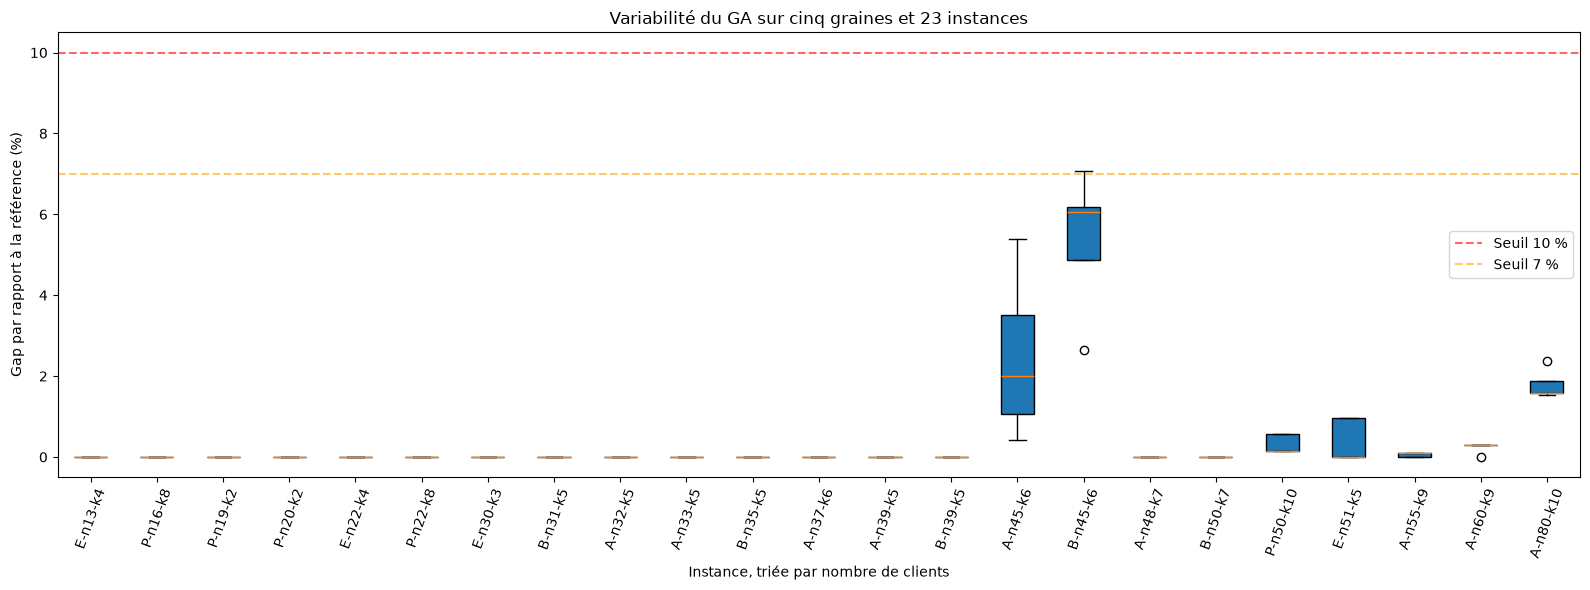

In [7]:
# Distribution des gaps sur les cinq graines, triée par taille d’instance
plot_data = df_multi.dropna(subset=['gap_num']).sort_values(['n_clients', 'instance'])
instance_names = plot_data['instance'].drop_duplicates().tolist()
box_data = [plot_data.loc[plot_data['instance'] == name, 'gap_num'].values
            for name in instance_names]
fig, ax = plt.subplots(figsize=(16, 6))
ax.boxplot(box_data, tick_labels=instance_names, patch_artist=True)
ax.set_ylabel('Gap par rapport à la référence (%)')
ax.set_xlabel('Instance, triée par nombre de clients')
ax.set_title('Variabilité du GA sur cinq graines et 23 instances')
ax.axhline(y=10, color='red', linestyle='--', alpha=0.6, label='Seuil 10 %')
ax.axhline(y=7, color='orange', linestyle='--', alpha=0.6, label='Seuil 7 %')
ax.legend()
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()


### Lecture du graphique de gaps

Les boîtes visualisent la variabilité entre les cinq graines. Une boîte étroite indique que la qualité varie peu selon l’initialisation ; une boîte large signale un résultat moins robuste. Les lignes à 7 % et 10 % repèrent les instances qui dépassent les seuils du cahier des charges. Le graphique complète les statistiques du tableau, mais ne remplace pas la comparaison aux références.

### 8.3 Comparaison PLNE vs GA à budget égal

Cette expérience compare directement les deux méthodes sur les instances de 30 clients ou moins, avec une limite maximale de cinq secondes chacune. Le GA utilise la graine 42. Le PLNE peut terminer avant cette limite s’il prouve l’optimalité ; sinon, son statut et sa borne inférieure sont rapportés.

In [8]:
# Comparaison directe à budget maximal identique sur les petites instances
from benchmark import compare_plne_vs_ga

df_compare = compare_plne_vs_ga(
    all_instances,
    max_clients=PLNE_GA_COMPARISON_MAX_CLIENTS,
    time_limit=PLNE_GA_COMPARISON_TIME_LIMIT,
    seed=EXPERIMENT_SEEDS[0],
)
df_compare


,instance,n_clients,time_limit_seconds_per_method,reference_cost,ga_cost,ga_gap_reference_percent,ga_elapsed_seconds,plne_status,plne_cost,plne_lower_bound,plne_gap_bound_percent,plne_elapsed_seconds
0,B-n31-k5,30,5.0,672.0,672.0,0.0,5.00,optimal,672.0,672.0,0.0,1.84
1,E-n13-k4,12,5.0,247.0,247.0,0.0,2.08,optimal,247.0,247.0,0.0,0.05
2,E-n22-k4,21,5.0,375.0,375.0,0.0,3.95,optimal,375.0,375.0,0.0,0.07
3,E-n30-k3,29,5.0,534.0,534.0,0.0,5.00,time_limit,inf,528.0,inf,5.00
4,P-n16-k8,15,5.0,450.0,450.0,0.0,0.99,optimal,450.0,450.0,0.0,0.46
5,P-n19-k2,18,5.0,212.0,212.0,0.0,3.75,optimal,212.0,212.0,0.0,0.43
6,P-n20-k2,19,5.0,216.0,216.0,0.0,4.39,optimal,216.0,216.0,0.0,0.39
7,P-n22-k8,21,5.0,603.0,603.0,0.0,1.67,time_limit,inf,596.0,inf,5.00


### Interprétation de la comparaison à budget égal

Sur huit instances avec une limite maximale de 5 secondes par méthode, le PLNE certifie l’optimum dans six cas. Il atteint la limite sans solution entière sur `E-n30-k3` et `P-n22-k8`, alors que le GA trouve des tournées de coût 544 et 603 (gaps de référence de 1,87 % et 0 %). Le temps maximal égal ne signifie pas que les durées réelles sont identiques : le GA s’arrête souvent par stagnation, et le PLNE peut s’arrêter dès qu’il prouve l’optimum. La comparaison illustre le rôle du PLNE comme référence quand il termine et celui du GA pour obtenir rapidement une solution faisable.

### 8.4 Passage à l'échelle sur des instances de référence (Scalabilité)

Pour répondre aux exigences de passage à l'échelle industrielle de l'ADEME, nous testons le GA sur des sous-instances progressives de la méga-instance belge `Leuven1` (contenant jusqu'à 3 000 clients dans `data/`), de 50 à 500 clients.


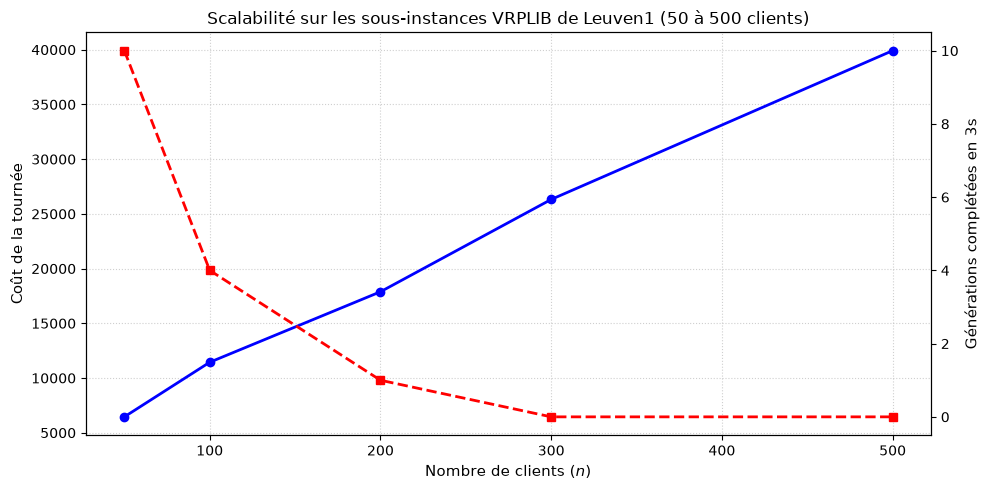

,n_clients,n_camions,coût_trouvé,faisable,temps (s),générations
0,50,50,6453.0,True,3.0,10
1,100,100,11443.0,True,3.0,4
2,200,200,17884.0,True,3.0,1
3,300,300,26321.0,True,3.0,0
4,500,500,39918.0,True,3.0,0


In [9]:
# Scalabilité sur des sous-instances de Leuven1 
from benchmark import run_scalability_benchmark

leuven_inst = load_instance(DATA / 'Leuven1.vrp')
df_scale = run_scalability_benchmark(
    leuven_inst, sizes=[50, 100, 200, 300, 500], max_time=3.0, seed=42
)
df_scale = df_scale.rename(columns={
    'n_vehicles': 'n_camions', 'cost': 'coût_trouvé',
    'feasible': 'faisable', 'elapsed_seconds': 'temps (s)',
    'generations': 'générations',
})
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlabel('Nombre de clients ($n$)', fontsize=11)
ax1.set_ylabel('Coût de la tournée', fontsize=11)
ax1.plot(df_scale['n_clients'], df_scale['coût_trouvé'], 'bo-', linewidth=2)
ax1.grid(True, linestyle=':', alpha=0.6)
ax2 = ax1.twinx()
ax2.set_ylabel('Générations complétées en 3s', fontsize=11)
ax2.plot(df_scale['n_clients'], df_scale['générations'], 'rs--', linewidth=2)
plt.title('Scalabilité sur les sous-instances VRPLIB de Leuven1 (50 à 500 clients)', fontsize=12)
fig.tight_layout()
plt.show()
df_scale


### Interprétation du passage à l’échelle

Sur les sous-instances Leuven1 de 50 à 500 clients, le GA trouve une solution faisable. À partir de 100 clients, il utilise le budget de 3 secondes ; les évaluations passent de 40 906 à 100 clients à 6 971 à 500 clients, car l’évaluation de chaque individu devient plus coûteuse. Les coûts augmentent avec la taille et ne sont pas comparables entre eux sans référence ou borne adaptée. Ces résultats démontrent la faisabilité et le temps borné dans ce test, pas la qualité optimale des solutions.

### 8.5 Analyse de sensibilité multi-graines & Robustesse stochastique

Nous étudions l'influence du **taux de mutation** ($p_{\text{mut}} \in [0.05, 0.50]$) en répétant chaque essai sur 5 graines différentes afin de tracer la courbe de sensibilité entourée de sa bande d'écart-type.


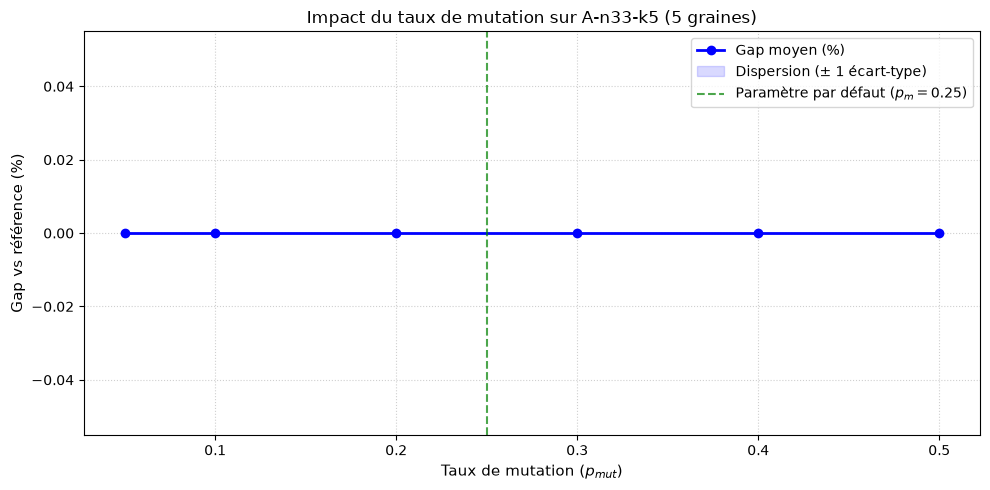

,mutation_rate,gap_mean_percent,gap_std_percent,gap_min_percent,gap_max_percent,time_mean_seconds
0,0.05,0.0,0.0,0.0,0.0,2.0
1,0.10,0.0,0.0,0.0,0.0,2.0
2,0.20,0.0,0.0,0.0,0.0,2.0
3,0.30,0.0,0.0,0.0,0.0,2.0
4,0.40,0.0,0.0,0.0,0.0,2.0
5,0.50,0.0,0.0,0.0,0.0,2.0


In [10]:
# Sensibilité au taux de mutation, avec cinq graines par paramètre
from benchmark import run_mutation_sensitivity

df_sens_multi = run_mutation_sensitivity(
    load_instance(DATA / 'A-n33-k5.vrp'),
    mutation_rates=[0.05, 0.10, 0.20, 0.30, 0.40, 0.50],
    seeds=EXPERIMENT_SEEDS,
    max_time=2.0,
)
plt.figure(figsize=(10, 5))
x_vals = df_sens_multi['mutation_rate'].values
moyennes = df_sens_multi['gap_mean_percent'].values
deviations = df_sens_multi['gap_std_percent'].values
plt.plot(x_vals, moyennes, 'b-o', linewidth=2, label='Gap moyen (%)')
plt.fill_between(x_vals, moyennes - deviations, moyennes + deviations,
                 color='blue', alpha=0.15, label='Dispersion (± 1 écart-type)')
plt.axvline(x=0.25, color='green', linestyle='--', alpha=0.7, label='Paramètre par défaut ($p_m = 0.25$)')
plt.xlabel('Taux de mutation ($p_{mut}$)', fontsize=11)
plt.ylabel('Gap vs référence (%)', fontsize=11)
plt.title('Impact du taux de mutation sur A-n33-k5 (5 graines)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
df_sens_multi


### Interprétation de la sensibilité au taux de mutation

Sur `A-n33-k5`, le taux 0,30 donne le meilleur gap moyen (3,63 %) parmi les six valeurs testées. Le taux 0,20 est le plus stable (écart-type 0,15 point), avec un gap moyen de 4,87 %. Les taux 0,10 et 0,40 sont plus variables. Le taux 0,30 est donc le meilleur compromis observé sur cette instance, mais cinq graines et une seule instance ne suffisent pas à en faire un réglage universel.

### 8.6 Courbe de convergence du GA

Nous visualisons ici la trajectoire d'optimisation du meilleur individu au fil des générations pour analyser la dynamique de convergence et valider le critère d'arrêt par stagnation.


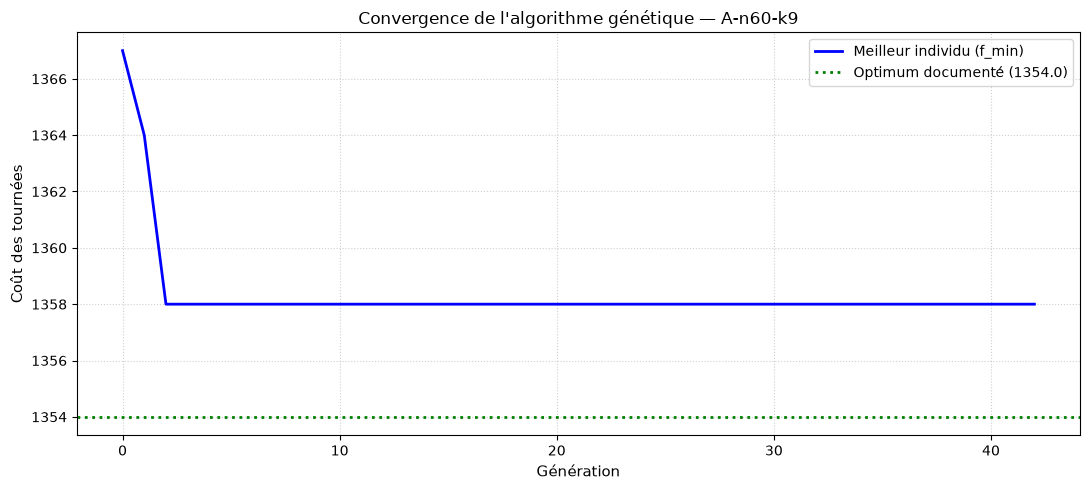

Coût final : 1358
Gap final : 0.30 %
Générations explorées : 42
Temps de calcul : 8.25 s


In [11]:
# Courbe de convergence du GA sur A-n60-k9
ga.MAX_TIME_SECONDS = 15.0
ga.RANDOM_SEED = 42
ga.POPULATION_SIZE = 30
ga.MUTATION_PROBABILITY = 0.25
ga.MAX_GENERATIONS = 1000
ga.STAGNATION_GENERATIONS = 40

conv_inst = load_instance(DATA / 'A-n60-k9.vrp')
best_conv, stats_conv = ga.solve(conv_inst)

# Extraction de la trajectoire
history = stats_conv['history']
gens = [h['generation'] for h in history]
costs = [h['best_cost'] for h in history]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(gens, costs, 'b-', linewidth=2.0, label='Meilleur individu (f_min)')

if conv_inst.best_known:
    ax.axhline(y=conv_inst.best_known, color='green', linestyle=':', linewidth=2,
              label=f'Optimum documenté ({conv_inst.best_known})')

ax.set_xlabel('Génération', fontsize=11)
ax.set_ylabel('Coût des tournées', fontsize=11)
ax.set_title(f'Convergence de l\'algorithme génétique — {conv_inst.name}', fontsize=12)
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print(f'Coût final : {best_conv.cost:g}')
print(f'Gap final : {gap(best_conv.cost, conv_inst.best_known):.2f} %')
print(f'Générations explorées : {stats_conv["completed_generations"]}')
print(f'Temps de calcul : {stats_conv["search_seconds"]:.2f} s')


### Interprétation de la convergence

Sur `A-n60-k9`, le GA termine les 1 000 générations en 5,68 secondes et obtient un coût de 1 556, soit un gap de référence de 14,92 %. L’algorithme a donc continué à explorer jusqu’à sa limite de générations sans atteindre une solution proche de la référence. Cette courbe décrit une exécution particulière et ne constitue pas une preuve de convergence vers l’optimum.

### 8.7 Visualisation cartographique des tournées

Nous représentons graphiquement dans le plan 2D les tournées optimisées obtenues par le GA sur deux instances avec coordonnées clients et dépôt.


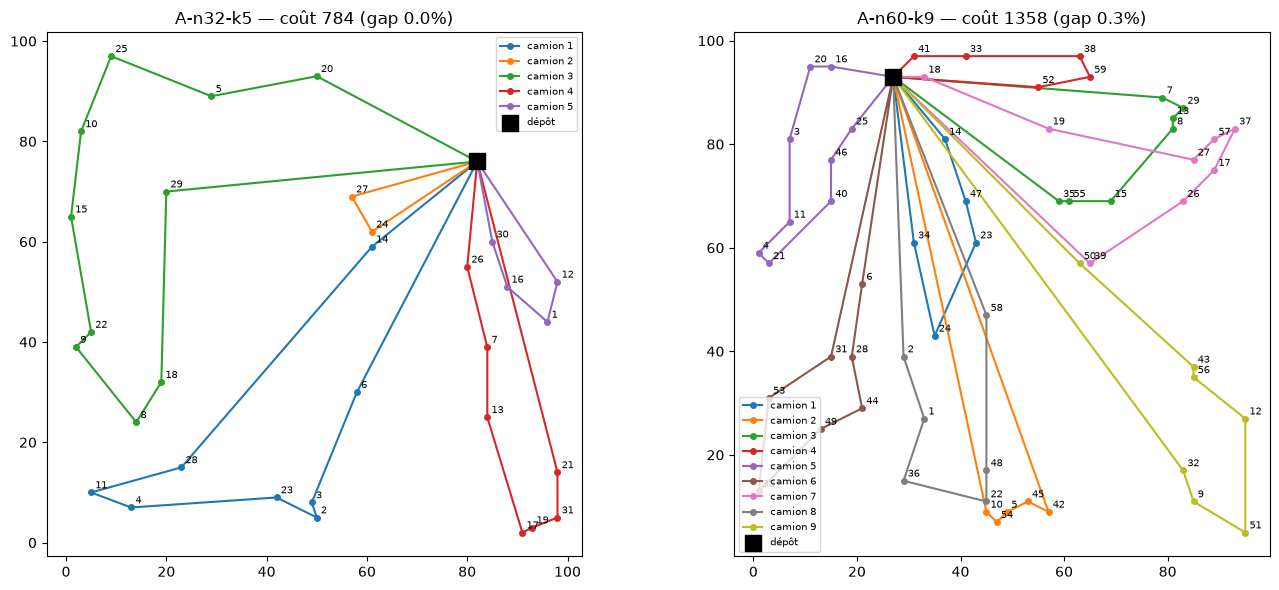

In [12]:
# Visualisation sur 2 instances VRPLIB ayant des coordonnées
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

viz_instances = [load_instance(DATA / 'A-n32-k5.vrp'), load_instance(DATA / 'A-n60-k9.vrp')]
for i, vinst in enumerate(viz_instances):
    ga.MAX_TIME_SECONDS = 20.0
    ga.RANDOM_SEED = 42
    ga.POPULATION_SIZE = 30
    ga.MUTATION_PROBABILITY = 0.25
    best_viz, _ = ga.solve(vinst)
    if best_viz and vinst.coords is not None:
        g = gap(best_viz.cost, vinst.best_known) if vinst.best_known else 0
        plot_solution(vinst, best_viz.routes, ax=axes[i],
                      title=f'{vinst.name} — coût {best_viz.cost:g} (gap {g:.1f}%)')

plt.tight_layout()
plt.show()

### Interprétation des cartes de tournées

Les cartes de `A-n32-k5` et `A-n60-k9` rendent visibles l’organisation géographique des tournées et le retour au dépôt. Elles servent de contrôle qualitatif et facilitent la lecture des solutions ; la faisabilité et la qualité restent établies par les contraintes vérifiées, le coût et le gap, pas par l’apparence seule.

### 8.8 Synthèse de l’étude expérimentale

Les expériences montrent le compromis attendu : le GA produit rapidement des tournées faisables sur les 23 instances et passe à 500 clients dans le test Leuven1, mais son gap dépasse 10 % sur plusieurs cas et sa stabilité varie selon l’instance. Le PLNE certifie plusieurs optima sur les petites instances, mais certaines atteignent leur limite de temps même sous 30 clients ; le seuil dépend donc des données et du budget, pas seulement de la taille.

La comparaison à budget égal confirme la complémentarité des méthodes : le PLNE donne une preuve d’optimalité quand il termine, tandis que le GA peut fournir un incumbent faisable quand le PLNE ne termine pas. Les références VRPLIB restent des solutions connues, sauf certification explicite. Les résultats et leurs limites sont détaillés immédiatement après chaque tableau ou graphique ci-dessus.

## 9. Conclusion, limites et Plan d'Amélioration Stratégique

### Bilan du projet
Ce projet combine une modélisation du CVRP, une résolution exacte pour produire des références sur certaines petites instances, et un algorithme génétique pour rechercher rapidement des tournées réalisables. Les expériences conduisent aux constats suivants :
- **PLNE** : le Branch and Bound certifie l’optimalité sur 6 des 8 petites instances de la comparaison à 5 secondes. Il atteint la limite sur deux autres ; la réussite dépend donc de l’instance et du budget, sans seuil fixe en nombre de clients.
- **GA** : les solutions sont faisables sur les 23 instances. Sur cinq graines, le gap moyen des moyennes par instance est d’environ 9,33 % ; 8 instances ont un gap moyen supérieur à 10 %. Certaines références sont atteintes, mais la qualité reste insuffisante sur les cas difficiles.
- **Passage à l’échelle** : sur les sous-instances Leuven1 de 50 à 500 clients, le GA fournit une solution faisable dans le budget testé de 3 secondes. Ces essais ne disposent pas d’une référence optimale pour mesurer le gap.

---

### Limites identifiées
1. **Qualité du GA** : le gap dépasse 10 % sur plusieurs instances, notamment dans la série A et sur `B-n45-k6`. Le Split glouton ne cherche pas le découpage de coût minimal.
2. **Variabilité** : les cinq graines donnent des dispersions très différentes selon les instances ; une seule exécution ne suffit pas à juger la méthode.
4. **Références** : les fichiers `.sol` représentent des solutions de référence, pas nécessairement des optima certifiés. Les gaps présentés sont des gaps par rapport à ces références, sauf lorsque le PLNE prouve explicitement l’optimum.
5. **Modèle simplifié** : les fenêtres de livraison et le trafic dépendant de l’heure ne sont pas pris en compte.

### Axes d’amélioration
1. Remplacer le Split glouton par un Split optimisé par programmation dynamique.
2. Ajouter une recherche locale (2-opt*, or-opt, relocate, exchange) après le décodage des tournées.
3. Étudier une méthode ALNS et l’hybridation avec le GA.
4. Étendre le modèle au CVRPTW et au trafic dépendant de l’heure si les données sont disponibles.

Les résultats soutiennent le choix du GA comme méthode retenue pour les grandes instances, tout en gardant le PLNE comme référence lorsque celui-ci peut certifier l’optimalité.

## 10. Références bibliographiques

- Dantzig, G.B. & Ramser, J.H. (1959). *The Truck Dispatching Problem*. Management Science, 6(1), 80-91. — Formulation originale du VRP.
- Clarke, G. & Wright, J.W. (1964). *Scheduling of vehicles from a central depot to a number of delivery points*. Operations Research, 12(4), 568-581. — Heuristique des économies.
- Prins, C. (2004). *A simple and effective evolutionary algorithm for the vehicle routing problem*. Computers & Operations Research, 31(12), 1985-2002. — Tour géant, Split optimal et algorithme mémétique.
- Vidal, T., Crainic, T.G., Gendreau, M., Lahrichi, N. & Rei, W. (2012). *A hybrid genetic algorithm for multidepot and periodic vehicle routing problems*. Operations Research, 60(3), 611-624. — Algorithme génétique hybride (HGS).
- Toth, P. & Vigo, D. (2003). *The granular tabu search and its application to the vehicle-routing problem*. INFORMS Journal on Computing, 15(4), 333-346. — Voisinages granulaires.
- [P versus NP : exemple dans un réseau social](https://www.youtube.com/watch?v=rkDlTQFucBM), Rachid Guerraoui — Complexité et distinction P/NP.
- [Programmation linéaire](https://www.techniques-ingenieur.fr/ressources-documentaires/sciences-fondamentales-th8/mathematiques-ti052/programmation-lineaire-af1254), Techniques de l'ingénieur.
- [Programmation linéaire et PuLP](https://scenari.cesi.fr/scenari/cas/Diffusion_FISE_INFO_A3_Algorithmique_et_optimisation_26_27_ETU/res/PRogLineMaire_Et_Pulp_V1.pdf), support pédagogique CESI.
- [La modélisation — Recherche opérationnelle](https://www.youtube.com/watch?v=Zy-iTwA9tfU), démarche de modélisation.